# HumTrans dataset exploration

**Project:** J26-DS-339 — Harmony-Oriented Melody Understanding for Genre-Aware Automatic Vocal Harmonization

This notebook audits the extracted HumTrans audio and MIDI files, validates the official split, summarizes audio and note-level properties, visualizes representative aligned examples, and records implications for the PP1 Data Analysis Report. It reads the dataset in place and does not alter the source recordings or annotations.

Run from the repository root with the project `uv` environment. The notebook uses the official files under `datasets/humtrans/downloads/`.

In [1]:
# Loading Analysis Libraries and Locating the Dataset
from pathlib import Path
from collections import Counter, defaultdict
import json, math, random, statistics, struct
import numpy as np
import soundfile as sf
import librosa
import librosa.display
import matplotlib.pyplot as plt

# Configure default appearance of plots created using Matplotlib
plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.25})

# Resolve paths when launched from either the repository root or notebooks/vishwa
_here = Path.cwd().resolve()
_candidates = [_here, *_here.parents]
PROJECT_ROOT = next((p for p in _candidates if (p / "datasets/humtrans/downloads/train_valid_test_keys.json").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate datasets/humtrans/downloads from the current directory")
DATA_ROOT = PROJECT_ROOT / "datasets/humtrans/downloads"
WAV_DIR = DATA_ROOT / "wav_data_sync_with_midi"
MIDI_DIR = DATA_ROOT / "midi_data"
SPLIT_PATH = DATA_ROOT / "train_valid_test_keys.json"
print(f"Project root: {PROJECT_ROOT}")
print(f"Dataset root: {DATA_ROOT}")

import mido
import pretty_midi


Project root: /Users/vishwaperera/Desktop/Research/Project/J26-DS-339
Dataset root: /Users/vishwaperera/Desktop/Research/Project/J26-DS-339/datasets/humtrans/downloads


## 1. File inventory and pairing validation

Files are paired by exact stem, following the naming convention documented with the dataset. Extra files and filename mismatches are surfaced rather than silently dropped.

In [2]:
# Inventorying Exact-Stem Audio and MIDI Pairs
# Load Wav file list, midi file list and the given splits
wav_paths = {p.stem: p for p in sorted(WAV_DIR.glob("*.wav"))}
midi_paths = {p.stem: p for p in sorted(MIDI_DIR.glob("*.mid"))}
splits = json.loads(SPLIT_PATH.read_text(encoding="utf-8"))

# Check if midi or wav files are missing
print("Folder counts:", {"WAV": len(wav_paths), "MIDI": len(midi_paths)})
print("Non-audio top-level files:", sorted(p.name for p in DATA_ROOT.iterdir() if p.is_file()))
print("WAV without MIDI:", len(wav_paths.keys() - midi_paths.keys()))
print("MIDI without WAV:", len(midi_paths.keys() - wav_paths.keys()))
print("WAV-only examples:", sorted(wav_paths.keys() - midi_paths.keys())[:10])
print("MIDI-only examples:", sorted(midi_paths.keys() - wav_paths.keys())[:10])
paired_keys = wav_paths.keys() & midi_paths.keys()

Folder counts: {'WAV': 14614, 'MIDI': 14614}
Non-audio top-level files: ['.DS_Store', '.gitattributes', 'README.md', 'train_valid_test_keys.json']
WAV without MIDI: 0
MIDI without WAV: 0
WAV-only examples: []
MIDI-only examples: []


## 2. Official split analysis

Check split sizes, duplicate keys, missing pair references, and possible composition-level overlap. Composition IDs are inferred from the second filename field; this is a naming-based diagnostic, not a claim about the dataset's full metadata.

In [3]:
# Checking Official Split Membership and Filename-Based Overlap
# Analyze splits and contents
split_sets = {name: set(keys) for name, keys in splits.items()}
assert set(splits) == {"TRAIN", "VALID", "TEST"}, f"Unexpected split names: {list(splits)}"

all_split_keys = [key for keys in splits.values() for key in keys]

print("Split counts:", {name: len(keys) for name, keys in splits.items()})
print("Unique split keys:", len(set(all_split_keys)), "duplicate assignments:", len(all_split_keys) - len(set(all_split_keys)))
print("Paired files missing a split:", len(paired_keys - set(all_split_keys)))
print("Split keys without a WAV/MIDI pair:", len(set(all_split_keys) - paired_keys))

# Calculate Split proportions
print("Split proportions:", {name: round(len(keys) / max(len(all_split_keys), 1) * 100, 2) for name, keys in splits.items()})

# Check Overlap between splits
def composition_id(key):
    parts = key.split("_")
    return parts[1] if len(parts) > 1 else "UNKNOWN"
composition_sets = {name: {composition_id(key) for key in keys} for name, keys in splits.items()}

# Calculate the intersection between two sets, identifying compositions that occur in both splits.
for a, b in [("TRAIN", "VALID"), ("TRAIN", "TEST"), ("VALID", "TEST")]:
    shared = composition_sets[a] & composition_sets[b]
    print(f"Composition IDs shared by {a}/{b}: {len(shared)}")
print("Distinct inferred compositions per split:", {name: len(ids) for name, ids in composition_sets.items()})

# Check singer overlaps between splits
speaker_sets = {name: {key.split("_")[0] for key in keys} for name, keys in splits.items()}
for a, b in [("TRAIN", "VALID"), ("TRAIN", "TEST"), ("VALID", "TEST")]:
    shared = speaker_sets[a] & speaker_sets[b]
    print(f"Singer IDs shared by {a}/{b}: {len(shared)} ({sorted(shared)})")


Split counts: {'TRAIN': 13080, 'VALID': 765, 'TEST': 769}
Unique split keys: 14614 duplicate assignments: 0
Paired files missing a split: 0
Split keys without a WAV/MIDI pair: 0
Split proportions: {'TRAIN': 89.5, 'VALID': 5.23, 'TEST': 5.26}
Composition IDs shared by TRAIN/VALID: 0
Composition IDs shared by TRAIN/TEST: 0
Composition IDs shared by VALID/TEST: 0
Distinct inferred compositions per split: {'TRAIN': 450, 'VALID': 25, 'TEST': 25}
Singer IDs shared by TRAIN/VALID: 10 (['F01', 'F02', 'F03', 'F04', 'F05', 'M01', 'M02', 'M03', 'M04', 'M05'])
Singer IDs shared by TRAIN/TEST: 10 (['F01', 'F02', 'F03', 'F04', 'F05', 'M01', 'M02', 'M03', 'M04', 'M05'])
Singer IDs shared by VALID/TEST: 10 (['F01', 'F02', 'F03', 'F04', 'F05', 'M01', 'M02', 'M03', 'M04', 'M05'])


## 3. Audio metadata and sampled recording characteristics

Read WAV headers for every recording. Signal-level peak and RMS checks use a reproducible sample of up to 100 files (up to the first five seconds per selected file), so near-full-scale peak/silence counts below describe that sample, not the full corpus.

In [4]:
# Inspecting All WAV Headers and a Reproducible Signal Sample
audio_rows = []

# Inspect Audio files
for key, path in wav_paths.items():
    try:
        info = sf.info(path)
        audio_rows.append({"key": key, "path": path, "samplerate": info.samplerate, "channels": info.channels,
                            "subtype": info.subtype, "duration": info.duration, "frames": info.frames, "format": info.format, "filesize": path.stat().st_size})
    except Exception as exc:
        audio_rows.append({"key": key, "path": path, "error": f"{type(exc).__name__}: {exc}"})
        
# Separate valid and error records
audio_errors = [r for r in audio_rows if "error" in r]
valid_audio = [r for r in audio_rows if "error" not in r]
print("Unreadable headers:", len(audio_errors), audio_errors[:5])

# Check sample rates, channels, and audio encoding
print("Sample-rate counts:", dict(Counter(r["samplerate"] for r in valid_audio)))
print("Channel counts:", dict(Counter(r["channels"] for r in valid_audio)))
print("Encoding counts:", dict(Counter((r["format"], r["subtype"]) for r in valid_audio)))

# Analyze recording durations
durations = np.array([r["duration"] for r in valid_audio], dtype=float)
print("Duration (s): min / median / mean / p95 / max =", *(round(float(x), 3) for x in [durations.min(), np.median(durations), durations.mean(), np.percentile(durations, 95), durations.max()]))
print("Total audio hours:", round(float(durations.sum() / 3600), 3))
print("Total WAV storage (GiB):", round(sum(r["filesize"] for r in valid_audio) / 1024**3, 3))

# Compare audio duration across splits
for split_name, keys in splits.items():
    d = [next((r["duration"] for r in valid_audio if r["key"] == k), np.nan) for k in keys]
    print(f"{split_name} duration: n={np.isfinite(d).sum()}, mean={np.nanmean(d):.2f}s, total={np.nansum(d)/3600:.2f}h")

# Randomly sample 100 recordings for signal checks
rng = random.Random(339)
character_sample = rng.sample(valid_audio, min(100, len(valid_audio)))
signal_rows = []
for row in character_sample:
    try:
        with sf.SoundFile(row["path"]) as f:
            segment = f.read(frames=min(5 * f.samplerate, f.frames), dtype="float32", always_2d=True)
        if segment.size:
            peak = float(np.max(np.abs(segment)))
            rms = float(np.sqrt(np.mean(segment.astype(np.float64) ** 2)))
            signal_rows.append({"key": row["key"], "peak": peak, "rms": rms})
    except Exception as exc:
        print("Signal sample read error:", row["key"], repr(exc))
peaks = np.array([r["peak"] for r in signal_rows])
rms_values = np.array([r["rms"] for r in signal_rows])

# View sample results
print(f"Signal sample: {len(signal_rows)} recordings; peak >= 0.999: {int((peaks >= 0.999).sum())}; peak < 1e-5: {int((peaks < 1e-5).sum())}")
print("Sample peak median / max:", round(float(np.median(peaks)), 4), round(float(peaks.max()), 4))
print("Sample RMS median / min:", round(float(np.median(rms_values)), 5), round(float(rms_values.min()), 5))


Unreadable headers: 0 []
Sample-rate counts: {44100: 14614}
Channel counts: {1: 14614}
Encoding counts: {('WAV', 'PCM_16'): 14614}
Duration (s): min / median / mean / p95 / max = 4.936 12.812 13.849 22.714 29.905
Total audio hours: 56.218
Total WAV storage (GiB): 16.625


TRAIN duration: n=13080, mean=13.81s, total=50.16h
VALID duration: n=765, mean=14.14s, total=3.01h
TEST duration: n=769, mean=14.29s, total=3.05h


Signal sample: 100 recordings; peak >= 0.999: 21; peak < 1e-5: 0
Sample peak median / max: 0.5637 1.0
Sample RMS median / min: 0.10176 0.02269


## 4. MIDI note analysis

Read notes with PrettyMIDI's tempo-aware conversion, cross-checked across the entire corpus against a Mido event reader (`scripts/audit_humtrans.py`). This replaces the custom parser used in the first notebook execution.

**Correction recorded 2026-10-21:** the old parser sorted tempo events by both tick and tempo value. At tick zero this could let the default 500,000 μs/beat override an explicit faster tempo, inflating note times. The previous 834 tail-overrun finding was a parser artifact, not a confirmed dataset defect. The research log retains the original finding and correction.

In [ ]:
# Reading Tempo-Aware Notes and Summarizing Annotation Properties
#The function returns a dictionary containing the file format, track count, timing resolution and extracted notes.
def parse_midi(path):
    """Use maintained MIDI timing conversion and preserve note velocities."""
    metadata = mido.MidiFile(path)
    if metadata.type == 2 or metadata.ticks_per_beat <= 0:
        raise ValueError("Independent sequences/SMPTE timing are unsupported")
    # Decode note timing with PrettyMIDI after checking the MIDI timeline format.
    parsed = pretty_midi.PrettyMIDI(str(path))
    notes = [(note.start, note.end, note.pitch, note.velocity)
            for instrument in parsed.instruments for note in instrument.notes]
    
    return {"format": metadata.type, "tracks": len(metadata.tracks),
            "division": metadata.ticks_per_beat, "notes": notes}

# Read every MIDI file and record failures
midi_rows, midi_errors = {}, []
for key, path in midi_paths.items():
    try:
        midi_rows[key] = parse_midi(path)
    except Exception as exc:
        midi_errors.append((key, f"{type(exc).__name__}: {exc}"))

# Combine notes from all recordings
notes = [(key, *note) for key, result in midi_rows.items() for note in result["notes"]]

# Create arrays for analysis
note_counts = np.array([len(result["notes"]) for result in midi_rows.values()], dtype=int)
pitches = np.array([note[3] for note in notes], dtype=int)
onsets = np.array([note[1] for note in notes], dtype=float)
note_durations = np.array([note[2] - note[1] for note in notes], dtype=float)

# Print the dataset summaries
print("MIDI parse failures:", len(midi_errors), midi_errors[:5])
print("MIDI track-count distribution:", dict(Counter(result["tracks"] for result in midi_rows.values())))
print("Total note events:", len(notes), "files with zero notes:", int((note_counts == 0).sum()))
print("Notes/file: min / median / mean / p95 / max =", *(round(float(x), 2) for x in [note_counts.min(), np.median(note_counts), note_counts.mean(), np.percentile(note_counts, 95), note_counts.max()]))
print("Pitch range (MIDI):", int(pitches.min()), "to", int(pitches.max()), "distinct pitches:", len(set(pitches)))
print("Onset (s): min / median / max =", *(round(float(x), 3) for x in [onsets.min(), np.median(onsets), onsets.max()]))
print("Duration (s): min / median / p95 / max =", *(round(float(x), 3) for x in [note_durations.min(), np.median(note_durations), np.percentile(note_durations, 95), note_durations.max()]))

# Compare MIDI note tails with paired audio durations using a 50 ms allowance.
print("Unclosed note-on events: see independent full-corpus audit report")
valid_audio_durations = {r["key"]: r["duration"] for r in valid_audio}
long_notes = [(key, end, valid_audio_durations.get(key, np.nan)) for key, start, end, pitch, vel in notes if key in valid_audio_durations and end > valid_audio_durations[key] + 0.05]
print("Notes ending >50ms after paired audio duration:", len(long_notes), "distinct files:", len({x[0] for x in long_notes}))
file_last_note_end = {key: max((note[1] for note in result["notes"]), default=0.0) for key, result in midi_rows.items()}
tail_overruns = {key: file_last_note_end[key] - valid_audio_durations[key] for key in file_last_note_end if key in valid_audio_durations and file_last_note_end[key] > valid_audio_durations[key] + 0.05}
overrun_values = np.array(list(tail_overruns.values()), dtype=float)
if len(overrun_values):
    print("Tail overrun median / p95 / max (s):", np.median(overrun_values), np.percentile(overrun_values, 95), overrun_values.max())
else:
    print("No MIDI tail overruns exceeding 50 ms were found.")
print("Tail overruns >0.5s / >1.0s:", int((overrun_values > .5).sum()), "/", int((overrun_values > 1.0).sum()))
print("Most common MIDI pitches:", Counter(pitches).most_common(12))


MIDI parse failures: 0 []
MIDI track-count distribution: {2: 10053, 1: 4561}
Total note events: 391595 files with zero notes: 0
Notes/file: min / median / mean / p95 / max = 11.0 25.0 26.8 43.0 58.0
Pitch range (MIDI): 26 to 88 distinct pitches: 60
Onset (s): min / median / max = 0.0 6.25 28.125
Duration (s): min / median / p95 / max = 0.101 0.355 1.186 3.462
Unclosed note-on events: see independent full-corpus audit report
Notes ending >50ms after paired audio duration: 0 distinct files: 0
No MIDI tail overruns exceeding 50 ms were found.
Tail overruns >0.5s / >1.0s: 0 / 0
Most common MIDI pitches: [(np.int64(64), 44711), (np.int64(62), 41853), (np.int64(67), 35963), (np.int64(60), 35880), (np.int64(69), 29064), (np.int64(57), 24768), (np.int64(65), 18452), (np.int64(55), 14854), (np.int64(72), 14830), (np.int64(59), 13866), (np.int64(71), 11083), (np.int64(74), 10139)]


## 5. Aligned visual examples

The first example is selected deterministically from valid paired files and has at least one reference note. The pitch contour uses YIN, a monophonic fundamental-frequency estimator suitable for these humming recordings; it is an exploratory audio estimate, not ground truth.

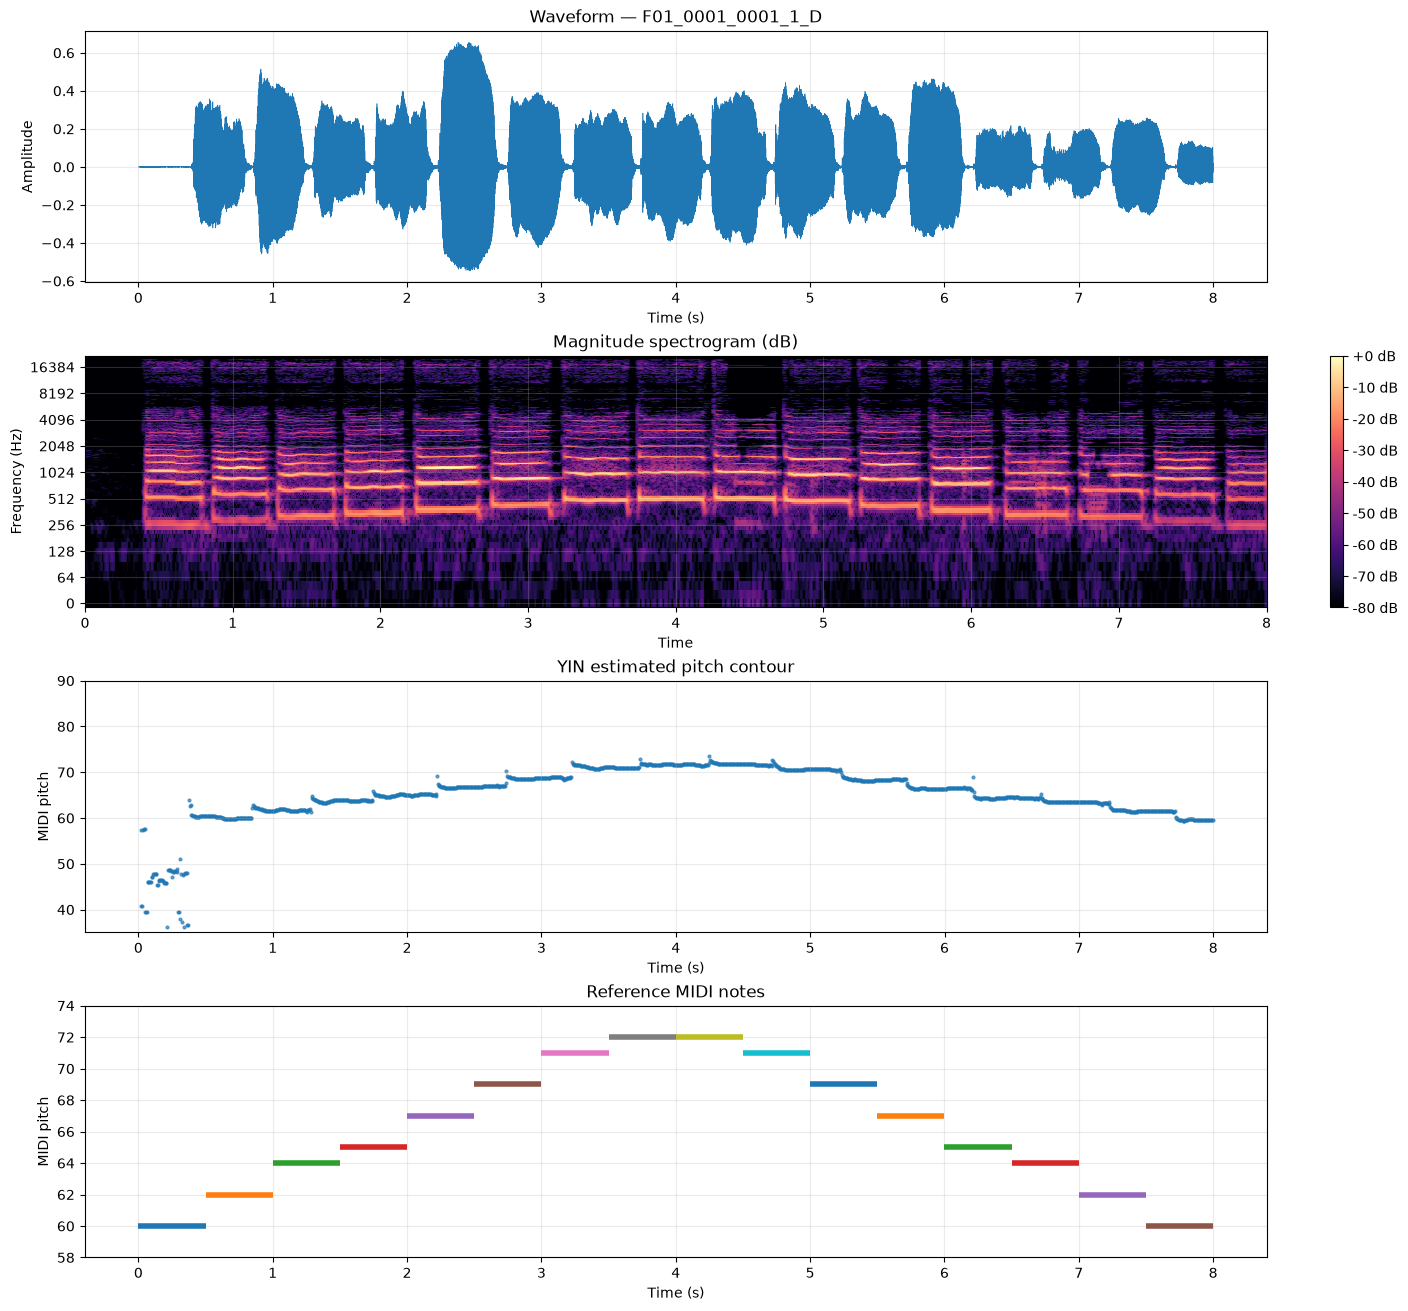

Example audio: 44100 Hz, 1 channel(s), 8.00 s; reference notes: 16


In [ ]:
# Visualizing One Recording with Estimated Pitch and Reference Notes
# Select & Load recording
example_key = next(key for key in sorted(paired_keys) if key in midi_rows and midi_rows[key]["notes"] and key in valid_audio_durations)
example_path = wav_paths[example_key]

y, sr = sf.read(example_path, dtype="float32", always_2d=True)
y_mono = y.mean(axis=1)
times = np.arange(len(y_mono)) / sr

# Create spectrogram - shows which frequencies are present as time passes.
D = librosa.stft(y_mono, n_fft=2048, hop_length=256)
db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

# Estimate pitch
f0 = librosa.yin(y_mono, fmin=librosa.note_to_hz("C2"), fmax=librosa.note_to_hz("C7"), sr=sr, frame_length=2048, hop_length=256)
f0_times = librosa.times_like(f0, sr=sr, hop_length=256)
f0_midi = librosa.hz_to_midi(f0)
reference = midi_rows[example_key]["notes"]

# Draw the 4 plots
fig, axes = plt.subplots(4, 1, figsize=(14, 13), constrained_layout=True)
axes[0].plot(times, y_mono, linewidth=0.45); axes[0].set(title=f"Waveform — {example_key}", xlabel="Time (s)", ylabel="Amplitude")
img = librosa.display.specshow(db, sr=sr, hop_length=256, x_axis="time", y_axis="log", ax=axes[1], cmap="magma"); axes[1].set(title="Magnitude spectrogram (dB)", ylabel="Frequency (Hz)"); fig.colorbar(img, ax=axes[1], format="%+2.0f dB")
axes[2].scatter(f0_times, f0_midi, s=4, alpha=0.65); axes[2].set(title="YIN estimated pitch contour", xlabel="Time (s)", ylabel="MIDI pitch", ylim=(35, 90))

for start, end, pitch, velocity in reference:
    axes[3].plot([start, end], [pitch, pitch], linewidth=4, solid_capstyle="butt")
axes[3].set(title="Reference MIDI notes", xlabel="Time (s)", ylabel="MIDI pitch", ylim=(min(n[2] for n in reference)-2, max(n[2] for n in reference)+2))
plt.show()
print(f"Example audio: {sr} Hz, {y.shape[1]} channel(s), {len(y_mono)/sr:.2f} s; reference notes: {len(reference)}")


## 5b. Corpus distributions

These histograms summarize all readable WAV headers and all parsed reference notes, rather than the single visual example. They describe recording length and note-label balance; they do not imply genre labels or continuous vocal F0 ground truth.

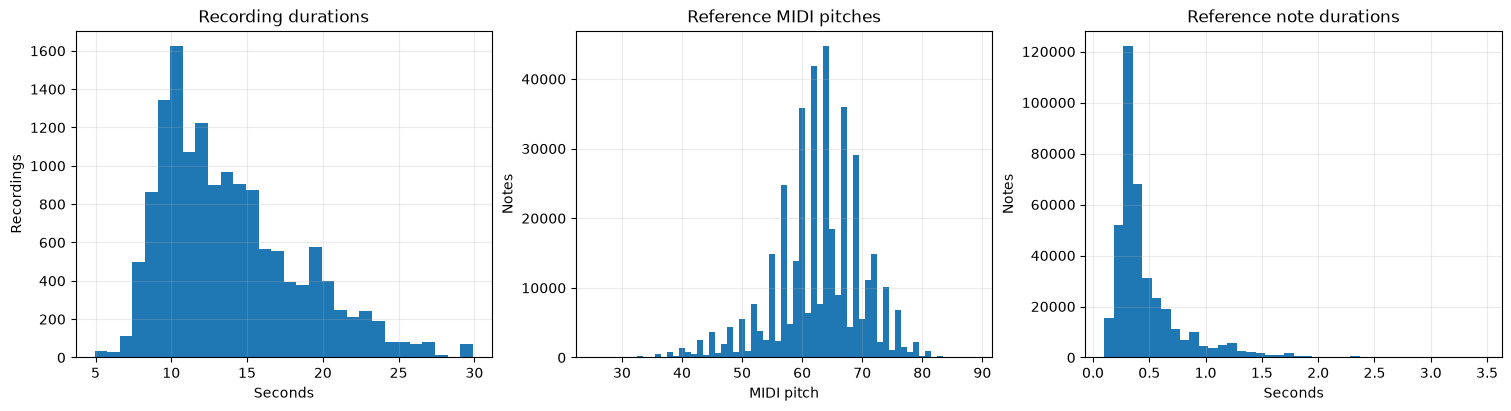

In [ ]:
# Plotting Corpus-Wide Recording and Note Distributions
# Examine all recordings
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
axes[0].hist(durations, bins=30)
axes[0].set(title="Recording durations", xlabel="Seconds", ylabel="Recordings")
axes[1].hist(pitches, bins=np.arange(pitches.min()-.5, pitches.max()+1.5))
axes[1].set(title="Reference MIDI pitches", xlabel="MIDI pitch", ylabel="Notes")
axes[2].hist(note_durations, bins=40)
axes[2].set(title="Reference note durations", xlabel="Seconds", ylabel="Notes")
plt.show()

## 6. Data quality, limitations, and PP1 report takeaways

Interpret signal-level checks as sample-based. HumTrans is described in its dataset README as 500 compositions and 1,000 music segments, but the extracted directory contains 14,614 recording/annotation pairs; recordings are repeated performances/variants and are not independent compositions. The supplied files and split JSON provide no explicit genre, chord, lyric, or harmony labels, so genre-aware harmonization targets and composition-level leakage need further verification against official metadata or additional annotation.

The final cell consolidates measured values for the report.

In [8]:
# Collecting Measured Dataset Findings for the Report
print("PP1 DATA ANALYSIS REPORT — MEASURED SUMMARY")
print(f"• {len(wav_paths):,} WAV and {len(midi_paths):,} MIDI files; {len(paired_keys):,} exact-stem pairs; {len(wav_paths.keys()-midi_paths.keys())} WAV-only and {len(midi_paths.keys()-wav_paths.keys())} MIDI-only files.")
print(f"• Official split sizes: train {len(splits['TRAIN']):,}, validation {len(splits['VALID']):,}, test {len(splits['TEST']):,}; {len(set(all_split_keys)):,} unique keys, {len(all_split_keys)-len(set(all_split_keys))} duplicate assignments, {len(paired_keys-set(all_split_keys))} pairs without a split.")
print(f"• Audio headers parsed: {len(valid_audio):,}/{len(wav_paths):,}; sample rate(s) {dict(Counter(r['samplerate'] for r in valid_audio))}; channels {dict(Counter(r['channels'] for r in valid_audio))}; total duration {durations.sum()/3600:.2f} h (median {np.median(durations):.2f} s/file).")
print(f"• MIDI: {len(midi_rows):,} parsed, {len(midi_errors)} parse failures, {len(notes):,} paired note events, {int((note_counts==0).sum())} files with no note events; pitch range {pitches.min()}–{pitches.max()} (MIDI), median note duration {np.median(note_durations):.3f} s.")
print(f"• Composition-ID overlap by filename across split pairs: train/valid {len(composition_sets['TRAIN'] & composition_sets['VALID'])}, train/test {len(composition_sets['TRAIN'] & composition_sets['TEST'])}, valid/test {len(composition_sets['VALID'] & composition_sets['TEST'])}; speaker-ID overlap: train/valid {len(speaker_sets['TRAIN'] & speaker_sets['VALID'])}, train/test {len(speaker_sets['TRAIN'] & speaker_sets['TEST'])}, valid/test {len(speaker_sets['VALID'] & speaker_sets['TEST'])}.")
print(f"• Signal sample (n={len(signal_rows)}): {int((peaks>=.999).sum())} near-full-scale peaks, {int((peaks<1e-5).sum())} near-silent clips. These are sample counts only.")
print("• Research limitation: the supplied files do not expose genre/harmony labels; verify annotation availability before claiming supervised genre-aware harmonization. Composition IDs are disjoint across the official splits by filename; singer IDs cross splits, so evaluate whether singer-independent generalization is required.")

print(f"• Corrected tempo-aware MIDI reading: {len(tail_overruns)} files with note tails >50 ms beyond audio; see the research log for the retracted initial parser finding.")


PP1 DATA ANALYSIS REPORT — MEASURED SUMMARY
• 14,614 WAV and 14,614 MIDI files; 14,614 exact-stem pairs; 0 WAV-only and 0 MIDI-only files.
• Official split sizes: train 13,080, validation 765, test 769; 14,614 unique keys, 0 duplicate assignments, 0 pairs without a split.
• Audio headers parsed: 14,614/14,614; sample rate(s) {44100: 14614}; channels {1: 14614}; total duration 56.22 h (median 12.81 s/file).
• MIDI: 14,614 parsed, 0 parse failures, 391,595 paired note events, 0 files with no note events; pitch range 26–88 (MIDI), median note duration 0.355 s.
• Composition-ID overlap by filename across split pairs: train/valid 0, train/test 0, valid/test 0; speaker-ID overlap: train/valid 10, train/test 10, valid/test 10.
• Signal sample (n=100): 21 near-full-scale peaks, 0 near-silent clips. These are sample counts only.
• Research limitation: the supplied files do not expose genre/harmony labels; verify annotation availability before claiming supervised genre-aware harmonization. Compo